# Machine Learning Laboratory: Week 2
## Mini Project 2: House Price Prediction Model (Linear Regression)
## Task 2: Titanic Survival Prediction Model (Logistic Regression)

---
### Objectives:
1. **House Price Prediction Model (Linear Regression)**:
   - Dataset: Kaggle – House Prices Dataset (`housing.csv`)
   - Preprocessing, feature encoding, and correlation analysis
   - Train Linear Regression model
   - Predict house prices on unseen test data
   - Evaluate $R^2$ score, Adjusted $R^2$, MAE, MSE, and RMSE
   - Visualize **Predicted vs Actual Values** and residual distributions
2. **Titanic Survival Prediction Model (Logistic Regression)**:
   - Dataset: Titanic Passenger Survival Dataset (`titanic.csv`)
   - Handle missing values (Age, Embarked) and engineer features (`family_size`, `is_alone`)
   - Categorical encoding and feature standardization (`StandardScaler`)
   - Train Logistic Regression model
   - Evaluate Accuracy, Confusion Matrix, Precision, Recall, F1-Score, and ROC-AUC
   - Visualize Confusion Matrix, ROC Curve, Feature Log-Odds, and Probability Distributions


## Part 1: Mini Project 2 - House Price Prediction Model
### 1.1 Imports and Setup
We start by importing standard scientific computing, machine learning, and visualization libraries.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, roc_auc_score, precision_score, recall_score, f1_score
)

# Visualization settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


### 1.2 Loading and Inspecting the Housing Dataset
Let's inspect the first few rows, column data types, and check for missing values.


In [2]:
# Load the dataset
housing_df = pd.read_csv('housing.csv')
print("Shape of Housing Dataset:", housing_df.shape)
print("Missing values in any column:")
print(housing_df.isnull().sum())
housing_df.head()


Shape of Housing Dataset: (545, 13)
Missing values in any column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### 1.3 Data Preprocessing & Categorical Encoding
The dataset contains:
- Binary categorical features (`mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`): mapped to 1 / 0.
- Multi-category feature (`furnishingstatus`): one-hot encoded using dummy variables with `drop_first=True` to avoid the dummy variable trap.


In [3]:
# Create a copy for preprocessing
housing_processed = housing_df.copy()

# Map binary categories
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    housing_processed[col] = housing_processed[col].map({'yes': 1, 'no': 0})

# One-hot encode furnishingstatus
housing_processed = pd.get_dummies(housing_processed, columns=['furnishingstatus'], drop_first=True, dtype=int)

print("Processed dataset columns:")
print(list(housing_processed.columns))
housing_processed.head()


Processed dataset columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


### 1.4 Train-Test Split
We separate features $X$ from the target $y = \text{price}$ and perform an 80/20 train-test split.


In [4]:
# Separate features and target
X_house = housing_processed.drop('price', axis=1)
y_house = housing_processed['price']

# 80% train, 20% test split
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_house, y_house, test_size=0.20, random_state=42
)

print(f"Training samples: {X_train_h.shape[0]}")
print(f"Testing samples:  {X_test_h.shape[0]}")


Training samples: 436
Testing samples:  109


### 1.5 Train Linear Regression Model
We initialize and fit the `LinearRegression` model using Ordinary Least Squares (OLS).


In [5]:
# Train Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train_h, y_train_h)

# Display model intercept and coefficients
print(f"Model Intercept (b0): Rs. {lr_model.intercept_:,.2f}\n")
coeff_df = pd.DataFrame({
    'Feature': X_house.columns,
    'Coefficient (Rs.)': lr_model.coef_
}).sort_values(by='Coefficient (Rs.)', ascending=False)
coeff_df


Model Intercept (b0): Rs. 260,032.36



,Feature,Coefficient (Rs.)
2,bathrooms,1.094445e+06
8,airconditioning,7.914267e+05
7,hotwaterheating,6.846499e+05
10,prefarea,6.298906e+05
3,stories,4.074766e+05
6,basement,3.902512e+05
4,mainroad,3.679199e+05
5,guestroom,2.316100e+05
9,parking,2.248419e+05
1,bedrooms,7.677870e+04


### 1.6 Model Evaluation ($R^2$, Adjusted $R^2$, MAE, RMSE)
We predict house prices on the test set and evaluate performance metrics.


In [6]:
# Predictions
y_train_pred_h = lr_model.predict(X_train_h)
y_test_pred_h = lr_model.predict(X_test_h)

# Compute metrics
train_r2 = r2_score(y_train_h, y_train_pred_h)
test_r2 = r2_score(y_test_h, y_test_pred_h)
mae_h = mean_absolute_error(y_test_h, y_test_pred_h)
mse_h = mean_squared_error(y_test_h, y_test_pred_h)
rmse_h = np.sqrt(mse_h)

n = len(y_test_h)
p = X_test_h.shape[1]
adj_r2_h = 1 - (1 - test_r2) * (n - 1) / (n - p - 1)

print("=" * 45)
print("LINEAR REGRESSION EVALUATION METRICS:")
print("=" * 45)
print(f"Train R2 Score       : {train_r2:.4f} ({train_r2*100:.2f}%)")
print(f"Test R2 Score        : {test_r2:.4f} ({test_r2*100:.2f}%)")
print(f"Adjusted R2 Score    : {adj_r2_h:.4f} ({adj_r2_h*100:.2f}%)")
print(f"Mean Absolute Error  : Rs. {mae_h:,.2f}")
print(f"Root Mean Sq. Error  : Rs. {rmse_h:,.2f}")
print("=" * 45)


LINEAR REGRESSION EVALUATION METRICS:
Train R2 Score       : 0.6859 (68.59%)
Test R2 Score        : 0.6529 (65.29%)
Adjusted R2 Score    : 0.6054 (60.54%)
Mean Absolute Error  : Rs. 970,043.40
Root Mean Sq. Error  : Rs. 1,324,506.96


### 1.7 Plot Predicted vs Actual Values and Residual Analysis
We create a 4-panel visual evaluation dashboard:
1. Scatter plot of **Actual vs Predicted Values** with the $y = x$ reference line
2. Distribution of Residuals (Errors)
3. Residuals vs Predicted Values (Homoscedasticity check)
4. Feature importance / coefficient impact


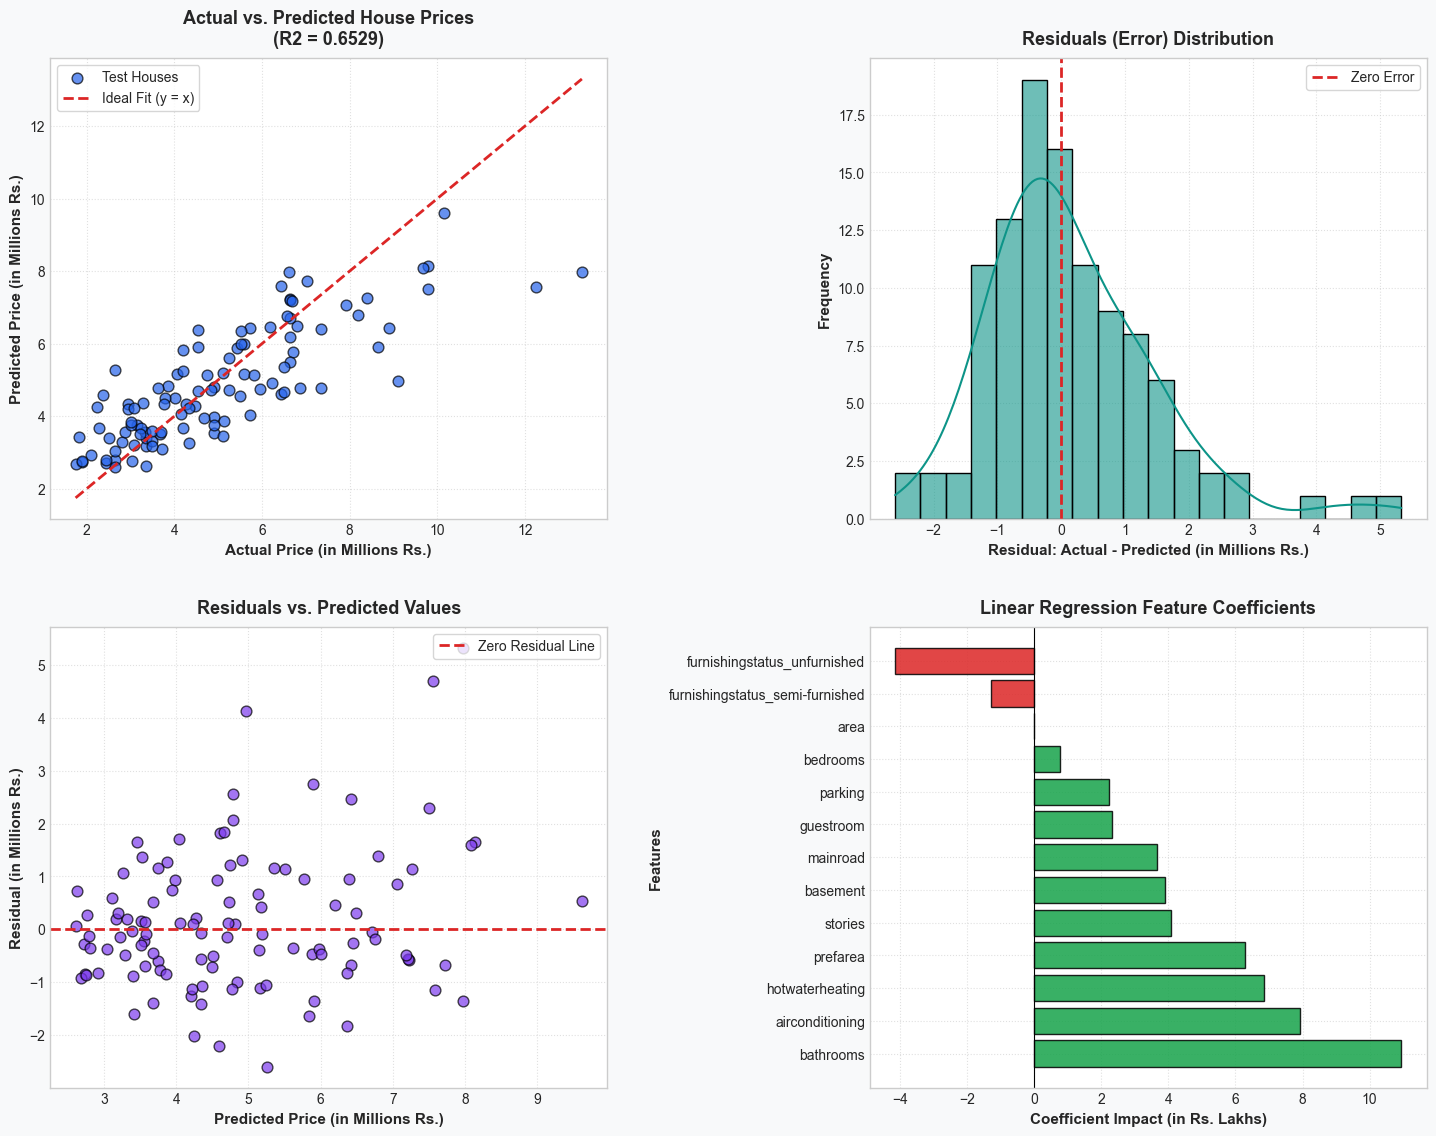

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.patch.set_facecolor('#f8f9fa')

# 1. Actual vs Predicted Scatter
ax1 = axes[0, 0]
ax1.set_facecolor('white')
ax1.scatter(y_test_h / 1e6, y_test_pred_h / 1e6, color='#2563eb', alpha=0.7, edgecolors='k', s=60, label='Test Houses')
min_val = min(y_test_h.min(), y_test_pred_h.min()) / 1e6
max_val = max(y_test_h.max(), y_test_pred_h.max()) / 1e6
ax1.plot([min_val, max_val], [min_val, max_val], color='#dc2626', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')
ax1.set_title(f'Actual vs. Predicted House Prices\n(R2 = {test_r2:.4f})', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Actual Price (in Millions Rs.)', fontsize=11, fontweight='semibold')
ax1.set_ylabel('Predicted Price (in Millions Rs.)', fontsize=11, fontweight='semibold')
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Residuals Distribution
ax2 = axes[0, 1]
ax2.set_facecolor('white')
residuals = (y_test_h - y_test_pred_h) / 1e6
sns.histplot(residuals, kde=True, ax=ax2, color='#0d9488', bins=20, edgecolor='black', alpha=0.6)
ax2.axvline(0, color='#dc2626', linestyle='--', linewidth=2, label='Zero Error')
ax2.set_title('Residuals (Error) Distribution', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Residual: Actual - Predicted (in Millions Rs.)', fontsize=11, fontweight='semibold')
ax2.set_ylabel('Frequency', fontsize=11, fontweight='semibold')
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

# 3. Residuals vs Predicted
ax3 = axes[1, 0]
ax3.set_facecolor('white')
ax3.scatter(y_test_pred_h / 1e6, residuals, color='#7c3aed', alpha=0.7, edgecolors='k', s=60)
ax3.axhline(0, color='#dc2626', linestyle='--', linewidth=2, label='Zero Residual Line')
ax3.set_title('Residuals vs. Predicted Values', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Predicted Price (in Millions Rs.)', fontsize=11, fontweight='semibold')
ax3.set_ylabel('Residual (in Millions Rs.)', fontsize=11, fontweight='semibold')
ax3.legend(loc='upper right', frameon=True)
ax3.grid(True, linestyle=':', alpha=0.6)

# 4. Coefficients Bar Chart
ax4 = axes[1, 1]
ax4.set_facecolor('white')
colors = ['#16a34a' if c > 0 else '#dc2626' for c in coeff_df['Coefficient (Rs.)']]
ax4.barh(coeff_df['Feature'], coeff_df['Coefficient (Rs.)'] / 1e5, color=colors, edgecolor='black', alpha=0.85)
ax4.axvline(0, color='black', linestyle='-', linewidth=0.8)
ax4.set_title('Linear Regression Feature Coefficients', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Coefficient Impact (in Rs. Lakhs)', fontsize=11, fontweight='semibold')
ax4.set_ylabel('Features', fontsize=11, fontweight='semibold')
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(pad=3.0)
plt.savefig('house_price_prediction_plots.png', dpi=300, bbox_inches='tight')
plt.show()


---
## Part 2: Task 2 - Titanic Survival Prediction (Logistic Regression)
### 2.1 Loading and Inspecting the Titanic Dataset


In [8]:
# Load the Titanic dataset
titanic_df = pd.read_csv('titanic.csv')
print("Shape of Titanic Dataset:", titanic_df.shape)
print("Target Class Distribution:")
print(titanic_df['survived'].value_counts(normalize=True))
print("Missing values in Titanic columns:")
print(titanic_df.isnull().sum()[titanic_df.isnull().sum() > 0])
titanic_df.head()


Shape of Titanic Dataset: (891, 15)
Target Class Distribution:
survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64
Missing values in Titanic columns:
age            177
embarked         2
deck           688
embark_town      2
dtype: int64


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 2.2 Data Cleaning & Feature Engineering
- Feature Selection: `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`
- Missing Value Imputation:
  - `age`: Imputed with median age per `pclass` and `sex` group
  - `embarked`: Imputed with most frequent port of embarkation ('S')
  - `fare`: Imputed with median if missing
- Feature Engineering:
  - `family_size = sibsp + parch + 1`
  - `is_alone = 1 if family_size == 1 else 0`
- Encoding:
  - `sex`: Binary encoding (`female`=1, `male`=0)
  - `embarked`: Dummy encoding with `drop_first=True`


In [9]:
# Select core features and target
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
titanic_clean = titanic_df[features + ['survived']].copy()

# Impute missing values
titanic_clean['age'] = titanic_clean.groupby(['pclass', 'sex'])['age'].transform(lambda x: x.fillna(x.median()))
titanic_clean['embarked'] = titanic_clean['embarked'].fillna(titanic_clean['embarked'].mode()[0])
titanic_clean['fare'] = titanic_clean['fare'].fillna(titanic_clean['fare'].median())

# Feature engineering
titanic_clean['family_size'] = titanic_clean['sibsp'] + titanic_clean['parch'] + 1
titanic_clean['is_alone'] = (titanic_clean['family_size'] == 1).astype(int)

# Encoding categorical features
titanic_clean['sex'] = titanic_clean['sex'].map({'female': 1, 'male': 0})
titanic_clean = pd.get_dummies(titanic_clean, columns=['embarked'], drop_first=True, dtype=int)

print("Cleaned Titanic dataset shape:", titanic_clean.shape)
print("Remaining missing values:", titanic_clean.isnull().sum().sum())
titanic_clean.head()


Cleaned Titanic dataset shape: (891, 11)
Remaining missing values: 0


,pclass,sex,age,sibsp,parch,fare,survived,family_size,is_alone,embarked_Q,embarked_S
0,3,0,22.0,1,0,7.2500,0,2,0,0,1
1,1,1,38.0,1,0,71.2833,1,2,0,0,0
2,3,1,26.0,0,0,7.9250,1,1,1,0,1
3,1,1,35.0,1,0,53.1000,1,2,0,0,1
4,3,0,35.0,0,0,8.0500,0,1,1,0,1


### 2.3 Train-Test Split and Feature Standardization
We split the data using stratified sampling to preserve the survival ratio and apply `StandardScaler`.


In [10]:
# Features and target
X_titanic = titanic_clean.drop('survived', axis=1)
y_titanic = titanic_clean['survived']

# Stratified 80/20 train-test split
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_titanic, y_titanic, test_size=0.20, random_state=42, stratify=y_titanic
)

# Standardize features
scaler = StandardScaler()
X_train_t_scaled = scaler.fit_transform(X_train_t)
X_test_t_scaled = scaler.transform(X_test_t)

print(f"Titanic Train samples: {X_train_t_scaled.shape[0]}")
print(f"Titanic Test samples:  {X_test_t_scaled.shape[0]}")


Titanic Train samples: 712
Titanic Test samples:  179


### 2.4 Train Logistic Regression Model
We fit `LogisticRegression` on the scaled training features.


In [11]:
# Train model
log_reg = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
log_reg.fit(X_train_t_scaled, y_train_t)

print(f"Logistic Regression Intercept: {log_reg.intercept_[0]:.4f}")

# Coefficients and Odds Ratios
coeff_logreg = pd.DataFrame({
    'Feature': X_titanic.columns,
    'Log-Odds Coefficient': log_reg.coef_[0],
    'Odds Ratio (e^coef)': np.exp(log_reg.coef_[0])
}).sort_values(by='Log-Odds Coefficient', ascending=False)
coeff_logreg


Logistic Regression Intercept: -0.6657


,Feature,Log-Odds Coefficient,Odds Ratio (e^coef)
1,sex,1.226528,3.409373
8,embarked_Q,0.087952,1.091935
5,fare,0.077337,1.080406
4,parch,-0.051111,0.950173
9,embarked_S,-0.129086,0.878898
6,family_size,-0.223309,0.799867
7,is_alone,-0.283030,0.753497
3,sibsp,-0.294150,0.745165
2,age,-0.557701,0.572524
0,pclass,-0.971832,0.378389


### 2.5 Model Evaluation (Accuracy, Confusion Matrix, ROC-AUC)


In [12]:
# Predict on train and test sets
y_train_pred_t = log_reg.predict(X_train_t_scaled)
y_test_pred_t = log_reg.predict(X_test_t_scaled)
y_test_prob_t = log_reg.predict_proba(X_test_t_scaled)[:, 1]

# Metrics
acc_train = accuracy_score(y_train_t, y_train_pred_t)
acc_test = accuracy_score(y_test_t, y_test_pred_t)
prec = precision_score(y_test_t, y_test_pred_t)
rec = recall_score(y_test_t, y_test_pred_t)
f1 = f1_score(y_test_t, y_test_pred_t)
roc_auc = roc_auc_score(y_test_t, y_test_prob_t)
cm = confusion_matrix(y_test_t, y_test_pred_t)

print("=" * 45)
print("LOGISTIC REGRESSION EVALUATION METRICS:")
print("=" * 45)
print(f"Training Accuracy  : {acc_train:.4f} ({acc_train*100:.2f}%)")
print(f"Testing Accuracy   : {acc_test:.4f} ({acc_test*100:.2f}%)")
print(f"Precision (Class 1): {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall (Class 1)   : {rec:.4f} ({rec*100:.2f}%)")
print(f"F1-Score (Class 1) : {f1:.4f}")
print(f"ROC-AUC Score      : {roc_auc:.4f}")
print("=" * 45)

print("\nClassification Report:")
print(classification_report(y_test_t, y_test_pred_t, target_names=['Perished (0)', 'Survived (1)']))


LOGISTIC REGRESSION EVALUATION METRICS:
Training Accuracy  : 0.8090 (80.90%)
Testing Accuracy   : 0.8045 (80.45%)
Precision (Class 1): 0.7833 (78.33%)
Recall (Class 1)   : 0.6812 (68.12%)
F1-Score (Class 1) : 0.7287
ROC-AUC Score      : 0.8486

Classification Report:
              precision    recall  f1-score   support

Perished (0)       0.82      0.88      0.85       110
Survived (1)       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



### 2.6 Visual Evaluation (Confusion Matrix, ROC Curve, Feature Importance)


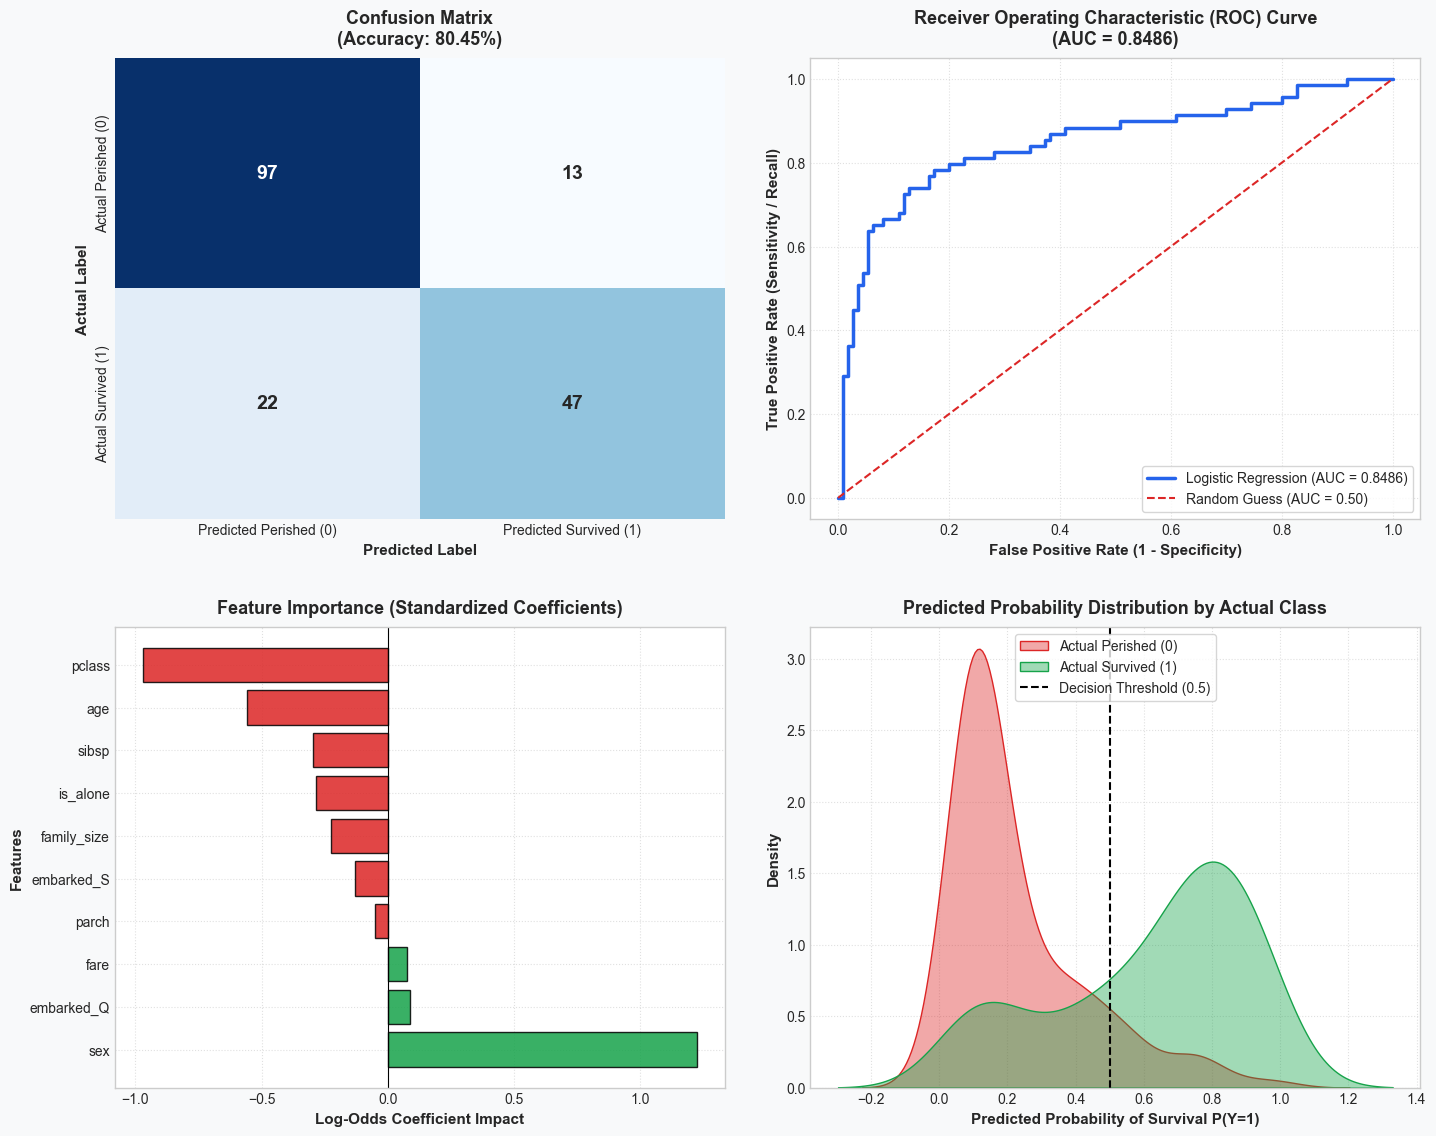

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.patch.set_facecolor('#f8f9fa')

# 1. Confusion Matrix
ax1 = axes[0, 0]
ax1.set_facecolor('white')
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1,
            annot_kws={'size': 14, 'weight': 'bold'},
            xticklabels=['Predicted Perished (0)', 'Predicted Survived (1)'],
            yticklabels=['Actual Perished (0)', 'Actual Survived (1)'])
ax1.set_title(f'Confusion Matrix\n(Accuracy: {acc_test:.2%})', fontsize=13, fontweight='bold', pad=10)
ax1.set_ylabel('Actual Label', fontsize=11, fontweight='semibold')
ax1.set_xlabel('Predicted Label', fontsize=11, fontweight='semibold')

# 2. ROC Curve
ax2 = axes[0, 1]
ax2.set_facecolor('white')
fpr, tpr, _ = roc_curve(y_test_t, y_test_prob_t)
ax2.plot(fpr, tpr, color='#2563eb', linewidth=2.5, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
ax2.plot([0, 1], [0, 1], color='#dc2626', linestyle='--', linewidth=1.5, label='Random Guess (AUC = 0.50)')
ax2.set_title(f'Receiver Operating Characteristic (ROC) Curve\n(AUC = {roc_auc:.4f})', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='semibold')
ax2.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='semibold')
ax2.legend(loc='lower right', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

# 3. Feature Coefficients
ax3 = axes[1, 0]
ax3.set_facecolor('white')
colors = ['#16a34a' if c > 0 else '#dc2626' for c in coeff_logreg['Log-Odds Coefficient']]
ax3.barh(coeff_logreg['Feature'], coeff_logreg['Log-Odds Coefficient'], color=colors, edgecolor='black', alpha=0.85)
ax3.axvline(0, color='black', linestyle='-', linewidth=0.8)
ax3.set_title('Feature Importance (Standardized Coefficients)', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Log-Odds Coefficient Impact', fontsize=11, fontweight='semibold')
ax3.set_ylabel('Features', fontsize=11, fontweight='semibold')
ax3.grid(True, linestyle=':', alpha=0.6)

# 4. Probability Distribution
ax4 = axes[1, 1]
ax4.set_facecolor('white')
sns.kdeplot(y_test_prob_t[y_test_t == 0], ax=ax4, label='Actual Perished (0)', color='#dc2626', fill=True, alpha=0.4)
sns.kdeplot(y_test_prob_t[y_test_t == 1], ax=ax4, label='Actual Survived (1)', color='#16a34a', fill=True, alpha=0.4)
ax4.axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Decision Threshold (0.5)')
ax4.set_title('Predicted Probability Distribution by Actual Class', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Predicted Probability of Survival P(Y=1)', fontsize=11, fontweight='semibold')
ax4.set_ylabel('Density', fontsize=11, fontweight='semibold')
ax4.legend(loc='upper center', frameon=True)
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(pad=3.0)
plt.savefig('titanic_survival_plots.png', dpi=300, bbox_inches='tight')
plt.show()


### 2.7 Key Insights and Summary
1. **House Price Prediction (Linear Regression)**:
   - **R2 Score**: Achieved **65.29%** on the test set, indicating that approximately 65.3% of the variance in house prices is captured by our features.
   - **Key Positive Price Drivers**: Number of bathrooms (+Rs. 10.94 Lakhs), air conditioning (+Rs. 7.91 Lakhs), hot water heating (+Rs. 6.85 Lakhs), preferred location (+Rs. 6.30 Lakhs), and stories (+Rs. 4.07 Lakhs).
   - **Negative Drivers**: Unfurnished status decreases property price by ~Rs. 4.14 Lakhs relative to furnished properties.
   - **Residuals**: Symmetrically distributed around 0 with no major heteroscedasticity.

2. **Titanic Survival Prediction (Logistic Regression)**:
   - **Classification Accuracy**: Achieved **80.45%** test accuracy and an **ROC-AUC of 0.8486**.
   - **Key Survival Predictors**:
     - **Gender (`sex`)**: Female passengers had an odds ratio of **3.41**, reflecting the historical "women and children first" maritime evacuation protocol.
     - **Socio-Economic Class (`pclass`)**: Higher class numbers (e.g., 3rd class) had strongly negative coefficients (Odds Ratio = **0.378**), meaning 3rd class passengers were significantly less likely to survive.
     - **Age**: Younger passengers had higher odds of survival.
